In [1]:
import os
import hashlib
import csv
from collections import defaultdict

def calculate_md5(file_path):
    """Tính mã MD5 hash của file để so sánh nội dung chính xác từng bit."""
    hasher = hashlib.md5()
    try:
        with open(file_path, 'rb') as f:
            # Đọc theo từng cụm 4096 bytes để tối ưu bộ nhớ cho file lớn
            for chunk in iter(lambda: f.read(4096), b''):
                hasher.update(chunk)
        return hasher.hexdigest()
    except Exception as e:
        print(f"Lỗi khi đọc file {file_path}: {e}")
        return None

def process_duplicate_images(root_dir):
    # Các định dạng ảnh cần quét
    image_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.gif', '.tiff', '.webp'}
    
    # Khởi tạo từ điển đếm số lượng trùng cho từng thư mục con để thống kê
    same_dir_dup_counts = {}
    for dirpath, _, _ in os.walk(root_dir):
        if dirpath != root_dir:
            # Chuẩn hóa đường dẫn tương đối (thay \ bằng / trên Windows)
            rel_dir = os.path.relpath(dirpath, root_dir).replace('\\', '/')
            same_dir_dup_counts[rel_dir] = 0
            
    diff_dir_dup_counts = {k: 0 for k in same_dir_dup_counts.keys()}
    
    # Gom nhóm danh sách đường dẫn ảnh theo mã hash MD5
    hash_to_paths = defaultdict(list)
    
    print(f"Đang quét thư mục: {root_dir}...")
    for dirpath, _, filenames in os.walk(root_dir):
        for filename in filenames:
            ext = os.path.splitext(filename)[1].lower()
            if ext in image_extensions:
                file_path = os.path.join(dirpath, filename)
                file_hash = calculate_md5(file_path)
                if file_hash:
                    hash_to_paths[file_hash].append(file_path)
                    
    same_dir_duplicates = []
    diff_dir_duplicates = []
    deleted_count = 0
    
    for file_hash, paths in hash_to_paths.items():
        if len(paths) <= 1:
            continue
            
        # Phân loại các đường dẫn file trùng theo thư mục chứa của chúng
        dir_groups = defaultdict(list)
        for p in paths:
            parent_dir = os.path.dirname(p)
            dir_groups[parent_dir].append(p)
            
        kept_files_in_dirs = []
        
        # 1. XỬ LÝ TRÙNG LẶP TRONG CÙNG THƯ MỤC (Xóa bớt và ghi log)
        for parent_dir, files_in_dir in dir_groups.items():
            # Giữ lại file đầu tiên làm ảnh gốc trong thư mục này
            kept_file = files_in_dir[0]
            kept_files_in_dirs.append(kept_file)
            
            # Xóa các file trùng còn lại trong cùng thư mục
            for dup_file in files_in_dir[1:]:
                # Ghi nhận cặp ảnh trùng
                same_dir_duplicates.append([os.path.basename(dup_file), os.path.basename(kept_file)])
                
                # Tiến hành xóa file
                try:
                    os.remove(dup_file)
                    deleted_count += 1
                    
                    # Cộng dồn số lượng ảnh trùng bị xóa của thư mục con này
                    rel_dir = os.path.relpath(parent_dir, root_dir).replace('\\', '/')
                    if rel_dir in same_dir_dup_counts:
                        same_dir_dup_counts[rel_dir] += 1
                except Exception as e:
                    print(f"Không thể xóa file {dup_file}: {e}")
                    
        # 2. XỬ LÝ TRÙNG LẶP Ở CÁC THƯ MỤC KHÁC NHAU (Chỉ ghi log, không xóa)
        if len(kept_files_in_dirs) > 1:
            reference_file = kept_files_in_dirs[0]
            ref_dir = os.path.relpath(os.path.dirname(reference_file), root_dir).replace('\\', '/')
            ref_name = os.path.basename(reference_file)
            
            for other_file in kept_files_in_dirs[1:]:
                other_dir = os.path.relpath(os.path.dirname(other_file), root_dir).replace('\\', '/')
                other_name = os.path.basename(other_file)
                
                diff_dir_duplicates.append([
                    other_name, other_dir,
                    ref_name, ref_dir
                ])
                
                # Cộng dồn thống kê trùng khác thư mục cho các thư mục liên quan
                if ref_dir in diff_dir_dup_counts:
                    diff_dir_dup_counts[ref_dir] += 1
                if other_dir in diff_dir_dup_counts:
                    diff_dir_dup_counts[other_dir] += 1
                
    # Ghi log ảnh trùng cùng thư mục ra file CSV (sử dụng utf-8-sig để đọc chữ có dấu trên Excel)
    same_dir_csv = 'ds_anh_trung_cung_thu_muc.csv'
    with open(same_dir_csv, mode='w', newline='', encoding='utf-8-sig') as f:
        writer = csv.writer(f)
        writer.writerow(['tên ảnh trùng 1', 'tên ảnh trùng 2'])
        writer.writerows(same_dir_duplicates)
        
    # Ghi log ảnh trùng khác thư mục ra file CSV
    diff_dir_csv = 'ds_trung_khac_thu_muc.csv'
    with open(diff_dir_csv, mode='w', newline='', encoding='utf-8-sig') as f:
        writer = csv.writer(f)
        writer.writerow(['tên ảnh trùng 1', 'thư mục chứa ảnh trùng 1', 'tên ảnh trùng 2', 'thư mục chứa ảnh trùng 2'])
        writer.writerows(diff_dir_duplicates)
        
    print("\n=== KẾT QUẢ XỬ LÝ ===")
    print(f"- Đã xóa thành công: {deleted_count} ảnh trùng lặp trong cùng thư mục.")
    print(f"- File thống kê trùng cùng thư mục: {same_dir_csv} ({len(same_dir_duplicates)} dòng)")
    print(f"- File thống kê trùng khác thư mục: {diff_dir_csv} ({len(diff_dir_duplicates)} dòng)")
    
    print("\n=== THỐNG KÊ SỐ LƯỢNG TRÙNG Ở MỖI THƯ MỤC CON ===")
    for subfolder in sorted(same_dir_dup_counts.keys()):
        same_count = same_dir_dup_counts[subfolder]
        diff_count = diff_dir_dup_counts[subfolder]
        print(f"- Thư mục '{subfolder}':")
        print(f"  + Số ảnh trùng cùng thư mục (đã xóa): {same_count}")
        print(f"  + Số ảnh trùng khác thư mục (chỉ ghi nhận): {diff_count}")

# ----------------- CHẠY THỬ NGHIỆM -----------------
root_directory = 'MyTrashNet'

if os.path.exists(root_directory):
    process_duplicate_images(root_directory)
else:
    print(f"Lỗi: Không tìm thấy thư mục '{root_directory}'. Hãy chắc chắn rằng thư mục này nằm cùng cấp với file notebook.")

Đang quét thư mục: MyTrashNet...

=== KẾT QUẢ XỬ LÝ ===
- Đã xóa thành công: 0 ảnh trùng lặp trong cùng thư mục.
- File thống kê trùng cùng thư mục: ds_anh_trung_cung_thu_muc.csv (0 dòng)
- File thống kê trùng khác thư mục: ds_trung_khac_thu_muc.csv (0 dòng)

=== THỐNG KÊ SỐ LƯỢNG TRÙNG Ở MỖI THƯ MỤC CON ===
- Thư mục 'cardboard':
  + Số ảnh trùng cùng thư mục (đã xóa): 0
  + Số ảnh trùng khác thư mục (chỉ ghi nhận): 0
- Thư mục 'glass':
  + Số ảnh trùng cùng thư mục (đã xóa): 0
  + Số ảnh trùng khác thư mục (chỉ ghi nhận): 0
- Thư mục 'metal':
  + Số ảnh trùng cùng thư mục (đã xóa): 0
  + Số ảnh trùng khác thư mục (chỉ ghi nhận): 0
- Thư mục 'paper':
  + Số ảnh trùng cùng thư mục (đã xóa): 0
  + Số ảnh trùng khác thư mục (chỉ ghi nhận): 0
- Thư mục 'plastic':
  + Số ảnh trùng cùng thư mục (đã xóa): 0
  + Số ảnh trùng khác thư mục (chỉ ghi nhận): 0
- Thư mục 'trash':
  + Số ảnh trùng cùng thư mục (đã xóa): 0
  + Số ảnh trùng khác thư mục (chỉ ghi nhận): 0


In [5]:
import os
import hashlib
import shutil
import csv

def calculate_md5(file_path):
    """Tính mã MD5 hash của file để so sánh chính xác nội dung ảnh."""
    hasher = hashlib.md5()
    try:
        with open(file_path, 'rb') as f:
            for chunk in iter(lambda: f.read(4096), b''):
                hasher.update(chunk)
        return hasher.hexdigest()
    except Exception as e:
        print(f"Lỗi khi đọc file {file_path}: {e}")
        return None

def copy_non_duplicate_images(dir_dest, dir_source):
    # Các định dạng ảnh được hỗ trợ
    image_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.gif', '.tiff', '.webp'}
    copied_records = []
    
    if not os.path.exists(dir_source):
        print(f"Lỗi: Thư mục nguồn '{dir_source}' không tồn tại.")
        return
    if not os.path.exists(dir_dest):
        print(f"Lỗi: Thư mục đích '{dir_dest}' không tồn tại.")
        return

    # Lấy danh sách tất cả các thư mục con trong thư mục nguồn (vd: glass, cardboard...)
    subdirs = [d for d in os.listdir(dir_source) if os.path.isdir(os.path.join(dir_source, d))]
    
    for sub in subdirs:
        sub_dir_dest = os.path.join(dir_dest, sub)
        sub_dir_source = os.path.join(dir_source, sub)
        
        # Đảm bảo thư mục con tương ứng bên MyTrashNet1 tồn tại (nếu chưa có thì tự động tạo)
        os.makedirs(sub_dir_dest, exist_ok=True)
        
        # 1. Tính mã hash của tất cả ảnh hiện có trong thư mục con của MyTrashNet1
        existing_hashes = set()
        print(f"\nĐang so khớp thư mục con: {sub}...")
        for filename in os.listdir(sub_dir_dest):
            ext = os.path.splitext(filename)[1].lower()
            if ext in image_extensions:
                file_path = os.path.join(sub_dir_dest, filename)
                file_hash = calculate_md5(file_path)
                if file_hash:
                    existing_hashes.add(file_hash)
                    
        # 2. Quét các ảnh trong thư mục con của MyTrashNet2
        for filename in os.listdir(sub_dir_source):
            ext = os.path.splitext(filename)[1].lower()
            if ext in image_extensions:
                file_path_src = os.path.join(sub_dir_source, filename)
                file_hash_src = calculate_md5(file_path_src)
                
                # Nếu ảnh này chưa từng xuất hiện trong thư mục con tương ứng của MyTrashNet1
                if file_hash_src and file_hash_src not in existing_hashes:
                    dest_filename = filename
                    name_part, ext_part = os.path.splitext(filename)
                    counter = 1
                    dest_file_path = os.path.join(sub_dir_dest, dest_filename)
                    
                    # Xử lý đụng độ tên file: nếu trùng tên nhưng khác nội dung, tự đổi tên thành file_1.jpg, file_2.jpg...
                    while os.path.exists(dest_file_path):
                        dest_filename = f"{name_part}_{counter}{ext_part}"
                        dest_file_path = os.path.join(sub_dir_dest, dest_filename)
                        counter += 1
                    
                    # Tiến hành copy file
                    try:
                        shutil.copy2(file_path_src, dest_file_path)
                        # Thêm hash của ảnh vừa copy vào tập hợp để không bị copy lặp lại nếu có ảnh trùng tiếp theo
                        existing_hashes.add(file_hash_src)
                        
                        # Ghi nhận lịch sử sao chép
                        copied_records.append([sub, filename, dest_filename])
                        print(f" -> Đã copy: {filename} -> {dest_filename}")
                    except Exception as e:
                        print(f" Lỗi khi sao chép {filename}: {e}")
                        
    # Ghi log kết quả sao chép ra file CSV (sử dụng utf-8-sig để đọc chữ tiếng Việt trên Excel không lỗi font)
    csv_filename = 'ket_qua_sao_chep.csv'
    with open(csv_filename, mode='w', newline='', encoding='utf-8-sig') as f:
        writer = csv.writer(f)
        writer.writerow(['thư mục con', 'tên file nguồn', 'tên file đích'])
        writer.writerows(copied_records)
        
    print("\n=== HOÀN THÀNH XỬ LÝ ===")
    print(f"- Tổng số ảnh đã sao chép thành công: {len(copied_records)}")
    print(f"- Chi tiết danh sách đã lưu vào file: {csv_filename}")

# ----------------- CHẠY THỬ NGHIỆM -----------------
# Chỉ định đường dẫn 2 thư mục lớn (nằm cùng cấp với file .ipynb của bạn)
dir_dest = 'MyTrashNet2'
dir_source = 'MyTrashNet1'

copy_non_duplicate_images(dir_dest, dir_source)

Lỗi: Thư mục nguồn 'MyTrashNet1' không tồn tại.


Xáo trộn và đổi tên file

In [3]:
import os
import random

# Đường dẫn thư mục chứa các thư mục con (bạn có thể thay đổi đường dẫn này)
root_dir = "MyTrashNet4Class_v2_AutoCropped"  # Hoặc dùng '.' nếu chạy ngay tại thư mục hiện tại

# Định dạng các tệp ảnh cần xử lý
IMAGE_EXTENSIONS = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

# (Tùy chọn) Nếu bạn muốn kết quả xáo trộn luôn giống nhau mỗi lần chạy code, hãy bỏ comment dòng dưới:
# random.seed(42)

# Duyệt qua tất cả các mục trong thư mục gốc
for folder_name in os.listdir(root_dir):
    folder_path = os.path.join(root_dir, folder_name)
    
    # Kiểm tra nếu là thư mục con
    if os.path.isdir(folder_path):
        # Lấy danh sách các file hình ảnh
        files = [
            f for f in os.listdir(folder_path) 
            if os.path.isfile(os.path.join(folder_path, f)) and f.lower().endswith(IMAGE_EXTENSIONS)
        ]
        
        # Xáo trộn danh sách file ngẫu nhiên trước khi đánh số thứ tự
        random.shuffle(files)
        
        # Bước 1: Đổi tên sang tên tạm thời để tránh trường hợp đè/trùng file khi file gốc đã có dạng tên tương tự
        temp_files = []
        for idx, file_name in enumerate(files, start=1):
            ext = os.path.splitext(file_name)[1].lower()
            old_path = os.path.join(folder_path, file_name)
            temp_name = f"__temp_{folder_name}_{idx:04d}{ext}"
            temp_path = os.path.join(folder_path, temp_name)
            os.rename(old_path, temp_path)
            temp_files.append((temp_path, ext))
            
        # Bước 2: Đổi tên chính thức thành dạng: tên_thư_mục_xxxx.ext
        for idx, (temp_path, ext) in enumerate(temp_files, start=1):
            new_name = f"{folder_name}_{idx:04d}{ext}"
            new_path = os.path.join(folder_path, new_name)
            os.rename(temp_path, new_path)
            
        print(f"✓ Đã xáo trộn và đổi tên {len(files)} hình ảnh trong thư mục '{folder_name}'")

print("Hoàn tất xáo trộn và đổi tên tất cả hình ảnh!")

✓ Đã xáo trộn và đổi tên 2048 hình ảnh trong thư mục 'glass'
✓ Đã xáo trộn và đổi tên 2051 hình ảnh trong thư mục 'metal'
✓ Đã xáo trộn và đổi tên 2051 hình ảnh trong thư mục 'paper'
✓ Đã xáo trộn và đổi tên 2069 hình ảnh trong thư mục 'plastic'
Hoàn tất xáo trộn và đổi tên tất cả hình ảnh!


📥 Đang tải session u2netp...


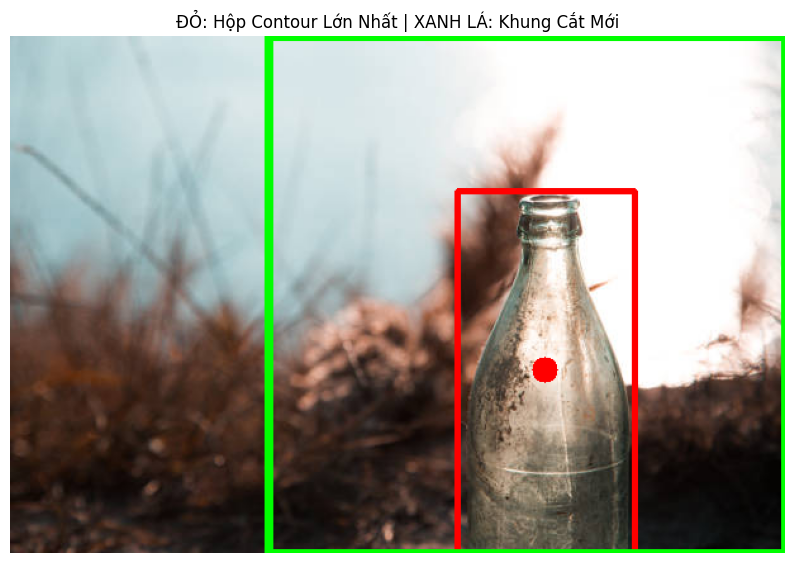

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from rembg import remove, new_session

# ĐIỀN ĐƯỜNG DẪN ẢNH BỊ LỖI LÁ CÂY VÀO ĐÂY:
img_path = 'MyTrashNet/glass/glass_1879.jpg' 

print("📥 Đang tải session u2netp...")
my_session = new_session("u2netp")

img = cv2.imread(img_path)
if img is not None:
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    debug_img = img_rgb.copy()
    h, w = img_rgb.shape[:2]
    a = min(h, w)
    
    # 1. Thu nhỏ để AI phân tích
    scale = 320.0 / max(h, w)
    small_img = cv2.resize(img_rgb, (0,0), fx=scale, fy=scale) if scale < 1.0 else img_rgb
    
    output_rgba = remove(small_img, session=my_session)
    alpha_mask = output_rgba[:, :, 3]
    
    # 2. BƯỚC NÂNG CẤP: TÌM HÒN ĐẢO LỚN NHẤT (Loại bỏ lá cây)
    # Chuyển mask thành ảnh nhị phân đen trắng
    _, binary_mask = cv2.threshold(alpha_mask, 10, 255, cv2.THRESH_BINARY)
    
    # Gom nhóm các pixel thành các cụm (contours)
    contours, _ = cv2.findContours(binary_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    if len(contours) > 0:
        # Lấy cụm có diện tích to nhất (Rác chính)
        largest_contour = max(contours, key=cv2.contourArea)
        
        # Lấy hộp bao quanh cụm to nhất đó
        x, y, w_box, h_box = cv2.boundingRect(largest_contour)
        
        small_cx = x + w_box // 2
        small_cy = y + h_box // 2
        
        # Nhân tỷ lệ lên ảnh thật
        cx = int(small_cx / scale)
        cy = int(small_cy / scale)
        
        # Tính toán góc để vẽ Khung Đỏ (Chỉ dùng để vẽ debug)
        x1_red = int(x / scale)
        y1_red = int(y / scale)
        x2_red = int((x + w_box) / scale)
        y2_red = int((y + h_box) / scale)
        
        crop_x = cx - a // 2
        crop_y = cy - a // 2
        
        # ÉP TRƯỢT
        crop_x = max(0, min(crop_x, w - a))
        crop_y = max(0, min(crop_y, h - a))
        
        # VẼ
        cv2.rectangle(debug_img, (x1_red, y1_red), (x2_red, y2_red), (255, 0, 0), 3) 
        cv2.circle(debug_img, (cx, cy), 10, (255, 0, 0), -1)
        cv2.rectangle(debug_img, (crop_x, crop_y), (crop_x + a, crop_y + a), (0, 255, 0), 5) 
        
    else:
        print("⚠️ Không tìm thấy vật nổi bật.")
        crop_x = w // 2 - a // 2
        crop_y = h // 2 - a // 2
        cv2.rectangle(debug_img, (crop_x, crop_y), (crop_x + a, crop_y + a), (0, 0, 255), 5) 

    plt.figure(figsize=(10, 10))
    plt.imshow(debug_img)
    plt.title("ĐỎ: Hộp Contour Lớn Nhất | XANH LÁ: Khung Cắt Mới")
    plt.axis('off')
    plt.show()

In [2]:
import os
import cv2
import numpy as np
from pathlib import Path
from tqdm import tqdm
from rembg import remove, new_session

# ==========================================
# 1. CẤU HÌNH ĐƯỜNG DẪN & THAM SỐ
# ==========================================
INPUT_DIR = 'MyTrashNet4Class_v2'                   # Thư mục chứa dataset gốc
OUTPUT_DIR = 'MyTrashNet4Class_v2_AutoCropped'      # Thư mục lưu dataset sau khi cắt
TARGET_SIZE = None                        # Đặt (224, 224) nếu muốn resize luôn cho model, hoặc None để giữ nguyên kích thước vuông gốc (a, a)
VALID_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

# Khởi tạo session u2netp 1 lần duy nhất
print("📥 Đang khởi tạo session u2netp...")
my_session = new_session("u2netp")


# ==========================================
# 2. HÀM TÍNH TOÁN VÙNG CẮT (BOUNDING BOX)
# ==========================================
def get_smart_crop_box(img_rgb, session, scale_target=320.0):
    """
    Xác định tọa độ crop_x, crop_y và kích thước a (hình vuông)
    dựa trên contour lớn nhất từ alpha mask của rembg.
    """
    h, w = img_rgb.shape[:2]
    a = min(h, w)
    
    # 1. Resize ảnh nhỏ để rembg chạy nhanh hơn
    scale = scale_target / max(h, w)
    small_img = cv2.resize(img_rgb, (0, 0), fx=scale, fy=scale) if scale < 1.0 else img_rgb
    
    # 2. Tách nền lấy mask
    output_rgba = remove(small_img, session=session)
    alpha_mask = output_rgba[:, :, 3]
    
    # 3. Tìm contour lớn nhất
    _, binary_mask = cv2.threshold(alpha_mask, 10, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(binary_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    if len(contours) > 0:
        largest_contour = max(contours, key=cv2.contourArea)
        # Bỏ qua nếu contour quá bé (nhiễu rác nhỏ)
        if cv2.contourArea(largest_contour) > 20:
            x, y, w_box, h_box = cv2.boundingRect(largest_contour)
            
            small_cx = x + w_box // 2
            small_cy = y + h_box // 2
            
            # Quy đổi tọa độ tâm về kích thước ảnh gốc
            cx = int(small_cx / scale)
            cy = int(small_cy / scale)
            
            crop_x = cx - a // 2
            crop_y = cy - a // 2
            
            # Giới hạn trong biên ảnh (ép trượt)
            crop_x = max(0, min(crop_x, w - a))
            crop_y = max(0, min(crop_y, h - a))
            
            return crop_x, crop_y, a, True

    # Fallback: Cắt giữa tâm nếu không phát hiện được vật nổi bật
    crop_x = (w - a) // 2
    crop_y = (h - a) // 2
    return crop_x, crop_y, a, False


# ==========================================
# 3. DUYỆT DATASET VÀ XỬ LÝ
# ==========================================
input_path = Path(INPUT_DIR)
output_path = Path(OUTPUT_DIR)

# Thu thập tất cả các file ảnh hợp lệ
image_files = [p for p in input_path.rglob('*') if p.suffix.lower() in VALID_EXTS]
print(f"🔍 Tìm thấy tổng cộng: {len(image_files)} ảnh.")

fallback_count = 0
error_count = 0

for file_p in tqdm(image_files, desc="Đang crop dataset"):
    # Xác định đường dẫn file đích (giữ nguyên cấu trúc thư mục con/class)
    rel_path = file_p.relative_to(input_path)
    save_file_path = output_path / rel_path
    save_file_path.parent.mkdir(parents=True, exist_ok=True)
    
    try:
        # Đọc ảnh an toàn (tránh lỗi font đường dẫn tiếng Việt/Windows)
        img = cv2.imdecode(np.fromfile(str(file_p), dtype=np.uint8), cv2.IMREAD_COLOR)
        if img is None:
            print(f"\n⚠️ Lỗi đọc file: {file_p}")
            error_count += 1
            continue
            
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        # Lấy tọa độ crop
        crop_x, crop_y, a, found = get_smart_crop_box(img_rgb, my_session)
        if not found:
            fallback_count += 1
            
        # Cắt ảnh vuông từ ảnh gốc
        cropped = img[crop_y : crop_y + a, crop_x : crop_x + a]
        
        # (Tùy chọn) Resize nếu bạn muốn đồng bộ kích thước chuẩn bị train mô hình
        if TARGET_SIZE is not None:
            cropped = cv2.resize(cropped, TARGET_SIZE, interpolation=cv2.INTER_AREA)
        
        # Lưu ảnh an toàn
        ext = file_p.suffix
        _, enc_img = cv2.imencode(ext, cropped)
        enc_img.tofile(str(save_file_path))
        
    except Exception as e:
        print(f"\n❌ Lỗi khi xử lý {file_p}: {e}")
        error_count += 1

print("\n" + "="*40)
print(" Hoàn tất xử lý dataset!")
print(f" Tổng số ảnh đã xử lý: {len(image_files) - error_count}")
print(f" Số ảnh dùng tâm rác chính: {len(image_files) - error_count - fallback_count}")
print(f" Số ảnh fallback cắt giữa tâm: {fallback_count}")
if error_count > 0:
    print(f"⚠️ Số ảnh bị lỗi: {error_count}")
print(f"📁 Dataset mới lưu tại: {OUTPUT_DIR}")
print("="*40)

📥 Đang khởi tạo session u2netp...
🔍 Tìm thấy tổng cộng: 8219 ảnh.


Đang crop dataset: 100%|██████████| 8219/8219 [57:40<00:00,  2.38it/s]  


 Hoàn tất xử lý dataset!
 Tổng số ảnh đã xử lý: 8219
 Số ảnh dùng tâm rác chính: 8219
 Số ảnh fallback cắt giữa tâm: 0
📁 Dataset mới lưu tại: MyTrashNet4Class_v2_AutoCropped


In [1]:
import os
import shutil
import csv
from PIL import Image
import imagehash
import numpy as np

# ==================== CẤU HÌNH ĐƯỜNG DẪN ====================
DIR_TRASHNET = "./TrashNet_AutoCropped"
DIR_MYTRASHNET = "./MyTrashNet4Class"

DIR_OUT_DUPLICATES = "./MyTrashNet_Duplicates"
DIR_OUT_UNIQUE = "./MyTrashNet_Unique"
CSV_OUTPUT_PATH = "./reports/duplicates_report.csv"

os.makedirs("./reports", exist_ok=True)
valid_exts = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
# =============================================================

# Tìm các thư mục con chung tên (glass, metal, paper, plastic)
subfolders_A = set(os.listdir(DIR_TRASHNET))
subfolders_B = set(os.listdir(DIR_MYTRASHNET))
common_classes = sorted(list(subfolders_A.intersection(subfolders_B)))

print(f"Các danh mục tìm thấy: {common_classes}\n")

duplicates_records = []
total_duplicates = 0
total_unique = 0

for cls_name in common_classes:
    path_A = os.path.join(DIR_TRASHNET, cls_name)
    path_B = os.path.join(DIR_MYTRASHNET, cls_name)
    
    if not (os.path.isdir(path_A) and os.path.isdir(path_B)):
        continue

    out_dup_class = os.path.join(DIR_OUT_DUPLICATES, cls_name)
    out_uniq_class = os.path.join(DIR_OUT_UNIQUE, cls_name)
    os.makedirs(out_dup_class, exist_ok=True)
    os.makedirs(out_uniq_class, exist_ok=True)
    
    print(f"--- Đang xử lý danh mục: [{cls_name}] ---")
    
    # 1. Quét pHash của toàn bộ ảnh trong TrashNet
    hashes_A = {}  # {hash_value: [(file_path, image_array_small), ...]}
    for fname in os.listdir(path_A):
        if fname.lower().endswith(valid_exts):
            full_path_A = os.path.join(path_A, fname)
            try:
                with Image.open(full_path_A) as img:
                    img_rgb = img.convert('RGB')
                    h = imagehash.phash(img_rgb)
                    # Lưu kèm ảnh thu nhỏ để đối chiếu pixel cực nhanh
                    img_small = np.array(img_rgb.resize((64, 64)))
                    hashes_A[full_path_A] = (h, img_small)
            except Exception as e:
                pass

    # 2. Quét MyTrashNet và đối chiếu
    found_in_cls = 0
    unique_in_cls = 0
    
    for fname in os.listdir(path_B):
        if fname.lower().endswith(valid_exts):
            full_path_B = os.path.join(path_B, fname)
            try:
                with Image.open(full_path_B) as img_b:
                    img_b_rgb = img_b.convert('RGB')
                    hb = imagehash.phash(img_b_rgb)
                    img_b_small = np.array(img_b_rgb.resize((64, 64)))
            except Exception as e:
                continue

            matched_file_A = None
            min_dist = 999
            
            # So sánh pHash với các ảnh TrashNet
            for p_a, (ha, img_a_small) in hashes_A.items():
                hash_dist = hb - ha
                # Nếu khoảng cách pHash <= 2 (rất giống nhau)
                if hash_dist <= 2:
                    # Kiểm tra độ lệch điểm ảnh thực tế (đảm bảo chắc chắn là cùng 1 ảnh)
                    pixel_diff = np.mean(np.abs(img_b_small.astype(float) - img_a_small.astype(float)))
                    if pixel_diff < 5.0:  # Ngưỡng lệch màu trung bình < 5/255
                        matched_file_A = p_a
                        min_dist = hash_dist
                        break
            
            if matched_file_A:
                found_in_cls += 1
                total_duplicates += 1
                shutil.copy2(full_path_B, os.path.join(out_dup_class, fname))
                
                duplicates_records.append({
                    "Danh mục": cls_name,
                    "Ảnh trùng (MyTrashNet)": fname,
                    "Đường dẫn MyTrashNet": full_path_B,
                    "Ảnh gốc (TrashNet)": os.path.basename(matched_file_A),
                    "Đường dẫn TrashNet": matched_file_A,
                    "Khoảng cách pHash": min_dist
                })
            else:
                unique_in_cls += 1
                total_unique += 1
                shutil.copy2(full_path_B, os.path.join(out_uniq_class, fname))
                
    print(f"  -> Trùng: {found_in_cls} ảnh | Không trùng: {unique_in_cls} ảnh\n")

# 3. Xuất file CSV
if duplicates_records:
    headers = [
        "Danh mục", 
        "Ảnh trùng (MyTrashNet)", 
        "Đường dẫn MyTrashNet", 
        "Ảnh gốc (TrashNet)", 
        "Đường dẫn TrashNet", 
        "Khoảng cách pHash"
    ]
    with open(CSV_OUTPUT_PATH, mode='w', newline='', encoding='utf-8-sig') as f:
        writer = csv.DictWriter(f, fieldnames=headers)
        writer.writeheader()
        writer.writerows(duplicates_records)
    print(f"Đã xuất báo cáo CSV tại: {CSV_OUTPUT_PATH}")

print("=" * 50)
print("HOÀN THÀNH!")
print(f"- Tổng số ảnh trùng: {total_duplicates} (đã lưu tại: {DIR_OUT_DUPLICATES})")
print(f"- Tổng số ảnh không trùng: {total_unique} (đã lưu tại: {DIR_OUT_UNIQUE})")
print("=" * 50)

Các danh mục tìm thấy: ['glass', 'metal', 'paper', 'plastic']

--- Đang xử lý danh mục: [glass] ---
  -> Trùng: 267 ảnh | Không trùng: 1745 ảnh

--- Đang xử lý danh mục: [metal] ---
  -> Trùng: 199 ảnh | Không trùng: 1817 ảnh

--- Đang xử lý danh mục: [paper] ---
  -> Trùng: 55 ảnh | Không trùng: 1961 ảnh

--- Đang xử lý danh mục: [plastic] ---
  -> Trùng: 276 ảnh | Không trùng: 1741 ảnh

Đã xuất báo cáo CSV tại: ./reports/duplicates_report.csv
HOÀN THÀNH!
- Tổng số ảnh trùng: 797 (đã lưu tại: ./MyTrashNet_Duplicates)
- Tổng số ảnh không trùng: 7264 (đã lưu tại: ./MyTrashNet_Unique)


In [2]:
import os
import shutil

# ==================== CẤU HÌNH ====================
DIR_UNIQUE = "./MyTrashNet_Unique"
VALID_EXTS = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
# ==================================================

# 1. Thu thập toàn bộ file ảnh từ các thư mục con
image_files = []
subdirs = []

for item in os.listdir(DIR_UNIQUE):
    item_path = os.path.join(DIR_UNIQUE, item)
    # Chỉ duyệt vào các thư mục con
    if os.path.isdir(item_path):
        subdirs.append(item_path)
        for fname in os.listdir(item_path):
            if fname.lower().endswith(VALID_EXTS):
                image_files.append(os.path.join(item_path, fname))

# Sắp xếp danh sách để thứ tự đánh số được đồng nhất và tuần tự
image_files.sort()

total_images = len(image_files)
print(f"Tìm thấy tổng cộng {total_images} ảnh trong {len(subdirs)} thư mục con.\n")

if total_images == 0:
    print("Không tìm thấy ảnh nào trong các thư mục con!")
else:
    # 2. Đưa ảnh ra ngoài thư mục gốc
    print("Đang tiến hành di chuyển và đổi tên ảnh...")
    for old_path in image_files:
        file_name = os.path.basename(old_path)       # Lấy lại tên file gốc (ví dụ: "cat.jpg")
        new_path = os.path.join(DIR_UNIQUE, file_name)
        
        shutil.move(old_path, new_path)
    print(f"-> Đã di chuyển thành công {total_images} ảnh ra: {DIR_UNIQUE}\n")

    # 3. Dọn dẹp/Xoá các thư mục con đã trống
    for sdir in subdirs:
        try:
            os.rmdir(sdir)
            print(f"Đã xoá thư mục con trống: [{os.path.basename(sdir)}]")
        except OSError:
            print(f"Bỏ qua (thư mục chưa rỗng): [{os.path.basename(sdir)}]")

print("\n" + "=" * 40)
print("HOÀN TẤT TẤT CẢ CÔNG VIỆC!")
print("=" * 40)

Tìm thấy tổng cộng 7264 ảnh trong 4 thư mục con.

Đang tiến hành di chuyển và đổi tên ảnh...
-> Đã di chuyển thành công 7264 ảnh ra: ./MyTrashNet_Unique

Đã xoá thư mục con trống: [glass]
Đã xoá thư mục con trống: [metal]
Đã xoá thư mục con trống: [paper]
Đã xoá thư mục con trống: [plastic]

HOÀN TẤT TẤT CẢ CÔNG VIỆC!


Kiểm tra ảnh trùng

In [1]:
# ==============================================================================
# CELL KIỂM TRA ẢNH TRÙNG LẶP (BẤT CHẤP KHÁC NHAU VỀ KÍCH THƯỚC/ĐỘ PHÂN GIẢI)
# ==============================================================================
import os
import csv
from pathlib import Path
from collections import defaultdict
from itertools import combinations
from PIL import Image
import imagehash
import numpy as np
from tqdm import tqdm

# 1. CẤU HÌNH ĐẦU VÀO & ĐẦU RA
# Tự động nhận diện cả 2 cách đặt tên thư mục
CANDIDATE_DIRS = ["./MyTrashNet4Class_v2"]
DATASET_DIR = next((d for d in CANDIDATE_DIRS if os.path.exists(d)), None)

if DATASET_DIR is None:
    raise FileNotFoundError("❌ Không tìm thấy thư mục 'MyTrashNet_4Class' hoặc 'MyTrashNet4Class'!")

OUTPUT_CSV = "./reports/ket_qua_kiem_tra_anh_trung.csv"
os.makedirs(os.path.dirname(OUTPUT_CSV), exist_ok=True)

# Ngưỡng phát hiện:
# - MAX_HASH_DIST <= 3: Độ lệch pHash tối đa (ảnh resize/nén nhẹ thường có dist từ 0 đến 2)
# - MAX_PIXEL_DIFF < 8.0: Độ lệch màu trung bình tối đa sau khi normalize về 64x64 (trên thang 0-255)
MAX_HASH_DIST = 3
MAX_PIXEL_DIFF = 8.0

VALID_EXTENSIONS = ('.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tiff')

print(f"🚀 Bắt đầu quét thư mục: {DATASET_DIR}")

# 2. QUÉT VÀ TÍNH PHASH CHO TOÀN BỘ ẢNH (BẢO TOÀN SCALE INVARIANCE)
records = []
print("⏳ Đang quét toàn bộ ảnh và tính toán Perceptual Hash...")

all_files = []
for root, _, files in os.walk(DATASET_DIR):
    for f in files:
        if f.lower().endswith(VALID_EXTENSIONS):
            all_files.append(os.path.join(root, f))

for file_path in tqdm(all_files, desc="Tính pHash"):
    try:
        with Image.open(file_path) as img:
            img_rgb = img.convert('RGB')
            orig_size = img.size  # (Width, Height) gốc của ảnh
            
            # pHash tự động chuyển đổi DCT không gian tần số -> Bất chấp kích thước ảnh
            ph = str(imagehash.phash(img_rgb))
            
            # Chuẩn hóa về 64x64 để làm chốt chặn đo sai lệch pixel
            small_arr = np.array(img_rgb.resize((64, 64), Image.Resampling.BILINEAR), dtype=np.float32)
            
            rel_path = os.path.relpath(file_path, DATASET_DIR).replace('\\', '/')
            label = rel_path.split('/')[0] if '/' in rel_path else "root"
            
            records.append({
                "filename": os.path.basename(file_path),
                "filepath": file_path,
                "label": label,
                "size_str": f"{orig_size[0]}x{orig_size[1]}",
                "phash": ph,
                "small_arr": small_arr
            })
    except Exception as e:
        continue

total_images = len(records)
print(f"✅ Đã nạp thành công {total_images:,} ảnh hợp lệ.")

# 3. THUẬT TOÁN MULTI-INDEX BUCKETING ĐỂ LỌC NHANH ỨNG VIÊN (CHỐNG TREO MÁY)
# Chia 64-bit hex (16 ký tự) thành 4 khối x 4 ký tự.
print("🔍 Đang gom nhóm các cặp ứng viên nghi vấn...")
buckets = defaultdict(list)
for idx, item in enumerate(records):
    ph = item["phash"]
    if len(ph) == 16:
        for b_i in range(4):
            chunk = ph[b_i * 4 : (b_i + 1) * 4]
            buckets[(b_i, chunk)].append(idx)

candidate_pairs = set()
for indices in buckets.values():
    if len(indices) >= 2:
        for i, j in combinations(indices, 2):
            candidate_pairs.add((min(i, j), max(i, j)))

print(f"📊 Đã lọc được {len(candidate_pairs):,} cặp ứng viên cần so sánh chi tiết.")

# 4. SO SÁNH CHI TIẾT & XÁC THỰC CẶP TRÙNG (KỂ CẢ KHÁC KÍCH THƯỚC)
duplicate_results = []

def hamming_dist(h1, h2):
    return bin(int(h1, 16) ^ int(h2, 16)).count('1')

for i, j in tqdm(candidate_pairs, desc="Kiểm tra đối sánh"):
    item1 = records[i]
    item2 = records[j]
    
    # Đo khoảng cách pHash
    h_dist = hamming_dist(item1["phash"], item2["phash"])
    if h_dist <= MAX_HASH_DIST:
        # Chốt chặn đối chứng pixel: đo sai khác màu trung bình giữa 2 ảnh sau khi normalize
        pix_diff = np.mean(np.abs(item1["small_arr"] - item2["small_arr"]))
        
        if pix_diff <= MAX_PIXEL_DIFF:
            is_same_size = (item1["size_str"] == item2["size_str"])
            is_same_label = (item1["label"] == item2["label"])
            
            size_status = "Cùng kích thước" if is_same_size else f"Khác kích thước ({item1['size_str']} vs {item2['size_str']})"
            issue_type = "Trùng cùng lớp" if is_same_label else "TRÙNG CHÉO LỚP (Sai nhãn)"
            
            duplicate_results.append({
                "Tên ảnh 1": item1["filename"],
                "Đường dẫn ảnh 1": item1["filepath"],
                "Kích thước ảnh 1": item1["size_str"],
                "Lớp ảnh 1": item1["label"],
                "Tên ảnh 2": item2["filename"],
                "Đường dẫn ảnh 2": item2["filepath"],
                "Kích thước ảnh 2": item2["size_str"],
                "Lớp ảnh 2": item2["label"],
                "Khoảng cách pHash": h_dist,
                "Độ lệch màu pixel (0-255)": round(float(pix_diff), 2),
                "Tình trạng kích thước": size_status,
                "Loại trùng lặp": issue_type
            })

# 5. XUẤT BÁO CÁO RA FILE CSV
print("\n" + "=" * 60)
if duplicate_results:
    headers = list(duplicate_results[0].keys())
    with open(OUTPUT_CSV, mode="w", newline="", encoding="utf-8-sig") as f:
        writer = csv.DictWriter(f, fieldnames=headers)
        writer.writeheader()
        writer.writerows(duplicate_results)
        
    diff_size_count = sum(1 for r in duplicate_results if "Khác kích thước" in r["Tình trạng kích thước"])
    cross_class_count = sum(1 for r in duplicate_results if "TRÙNG CHÉO LỚP" in r["Loại trùng lặp"])
    
    print(f"🎉 HOÀN THÀNH KIỂM TRA!")
    print(f"- Tổng số cặp ảnh trùng phát hiện: {len(duplicate_results):,} cặp")
    print(f"- Trong đó có: {diff_size_count:,} cặp trùng nhưng KHÁC NHAU KÍCH THƯỚC")
    print(f"- Trong đó có: {cross_class_count:,} cặp TRÙNG CHÉO LỚP (Cần xem lại nhãn)")
    print(f"📁 Báo cáo đã được lưu tại: {os.path.abspath(OUTPUT_CSV)}")
else:
    print("✅ Không tìm thấy cặp ảnh nào trùng lặp theo tiêu chí đã đặt!")
print("=" * 60)

🚀 Bắt đầu quét thư mục: ./MyTrashNet4Class_v2
⏳ Đang quét toàn bộ ảnh và tính toán Perceptual Hash...


Tính pHash: 100%|██████████| 8226/8226 [03:23<00:00, 40.46it/s]


✅ Đã nạp thành công 8,226 ảnh hợp lệ.
🔍 Đang gom nhóm các cặp ứng viên nghi vấn...
📊 Đã lọc được 7,409 cặp ứng viên cần so sánh chi tiết.


Kiểm tra đối sánh: 100%|██████████| 7409/7409 [00:00<00:00, 2411391.20it/s]



🎉 HOÀN THÀNH KIỂM TRA!
- Tổng số cặp ảnh trùng phát hiện: 7 cặp
- Trong đó có: 1 cặp trùng nhưng KHÁC NHAU KÍCH THƯỚC
- Trong đó có: 0 cặp TRÙNG CHÉO LỚP (Cần xem lại nhãn)
📁 Báo cáo đã được lưu tại: c:\Users\HP\Downloads\KLTN (code)\reports\ket_qua_kiem_tra_anh_trung.csv
